In [27]:
%run ../Preprocessing/Preprocessing.ipynb

--------------PREPROCESSING:  ORIGINAL --------------
Time Taken ( Mean ):  0.04360461235046387


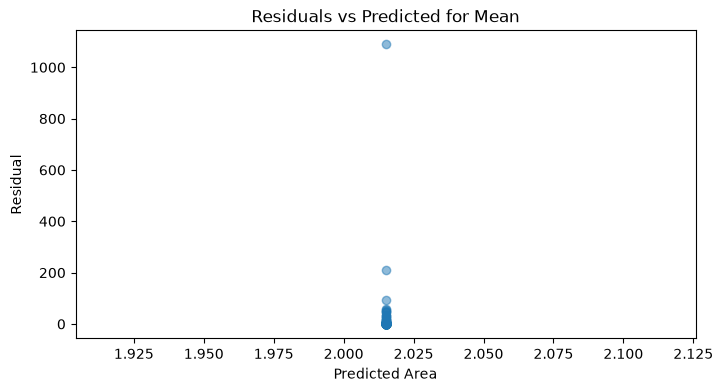

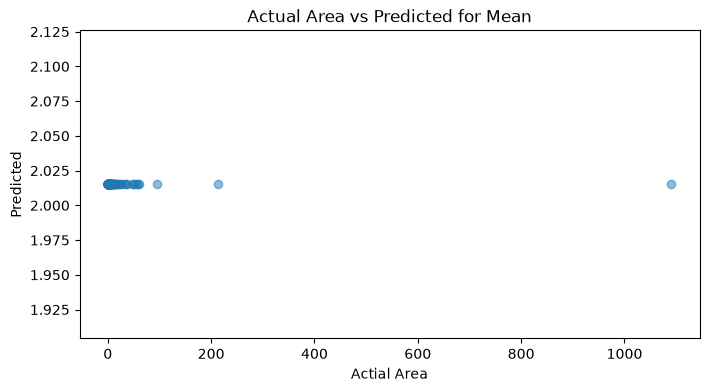

Time Taken ( Median ):  0.02377605438232422


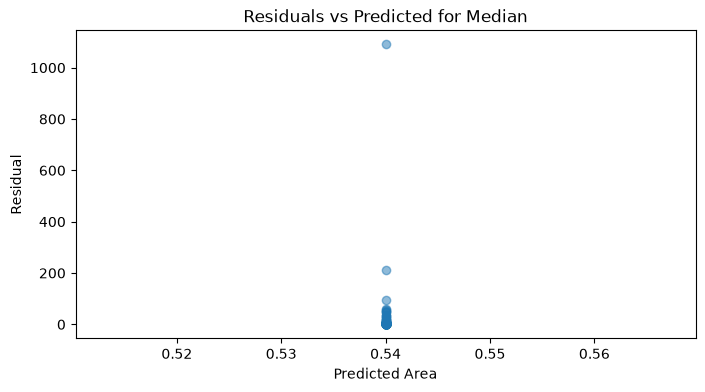

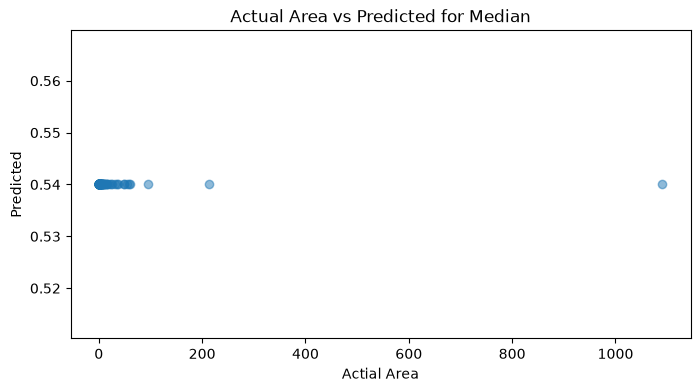

Time Taken ( Linear Regression ):  0.028153657913208008


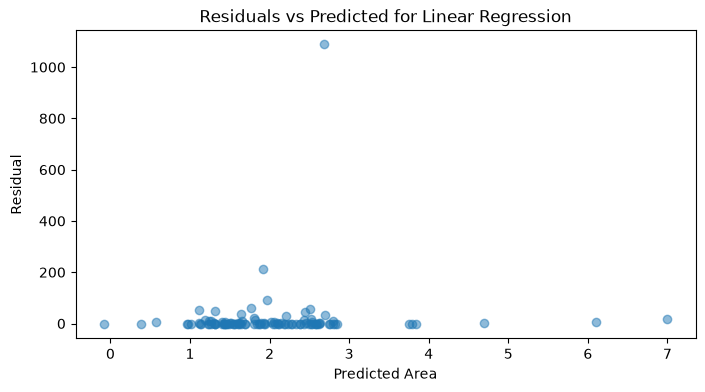

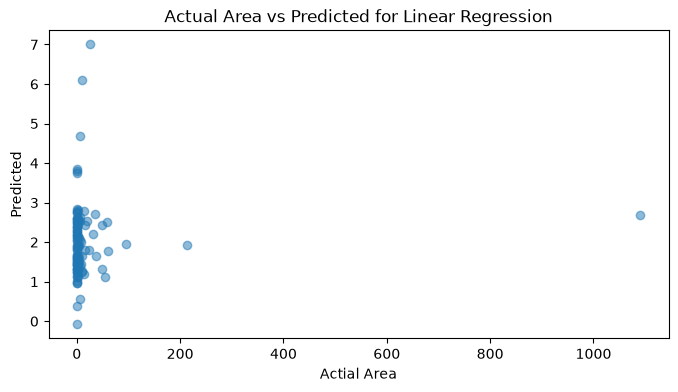

Time Taken ( Ridge ):  0.023011207580566406


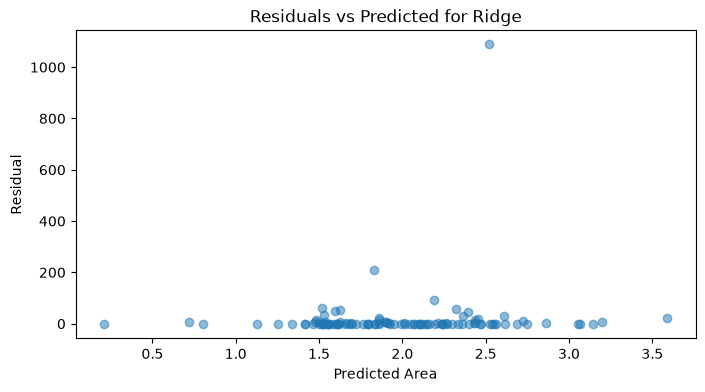

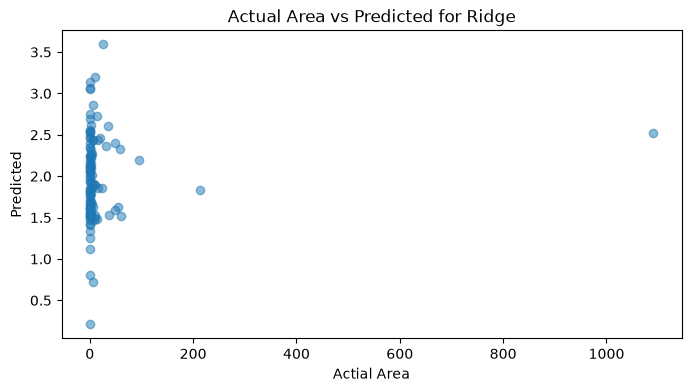

Time Taken ( KNN n = 3 ):  0.028438568115234375


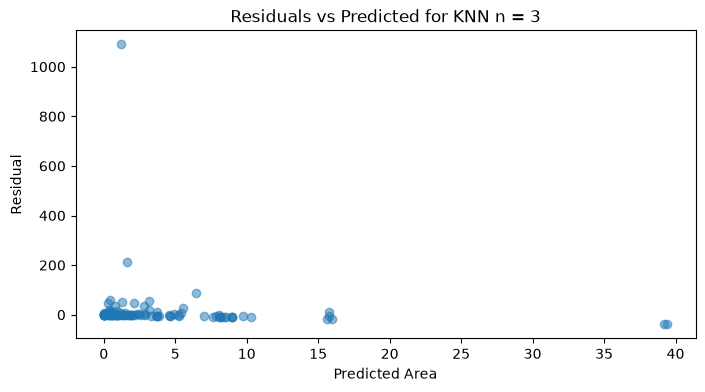

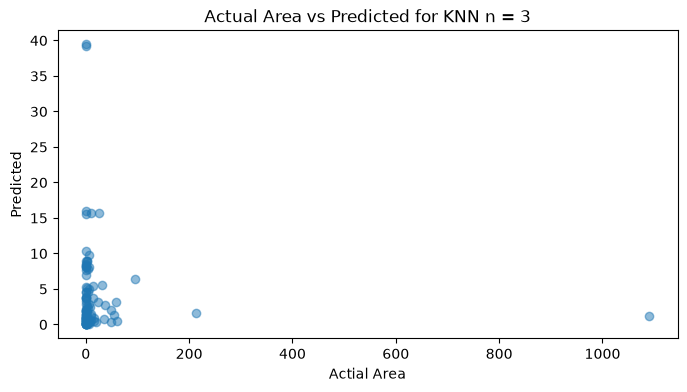

Time Taken ( KNN n = 7 ):  0.03486895561218262


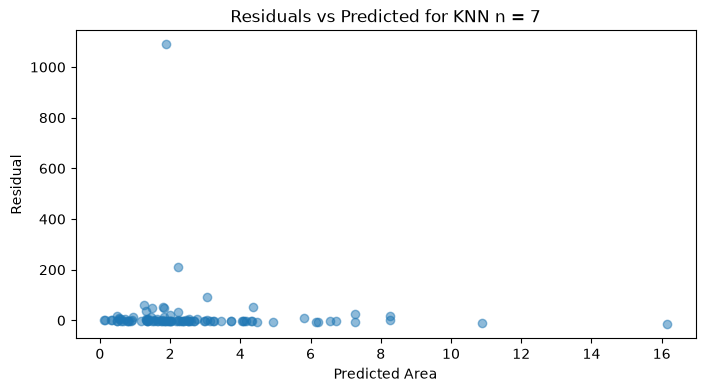

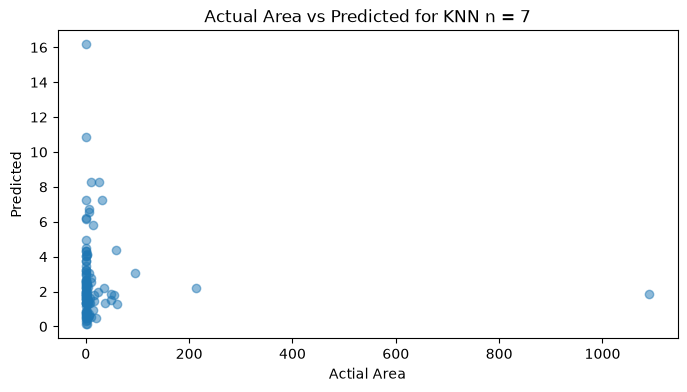

Time Taken ( KNN n = 21 ):  0.025178909301757812


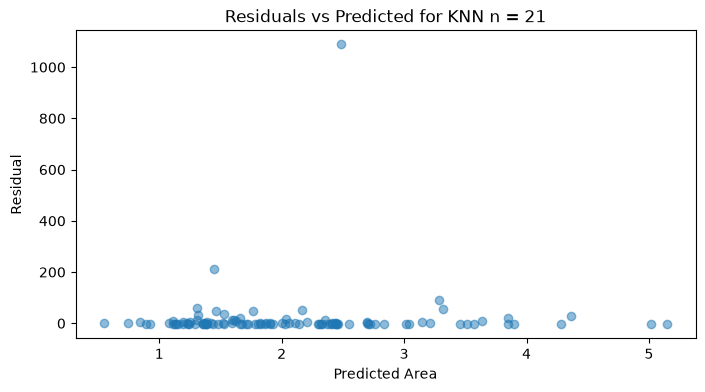

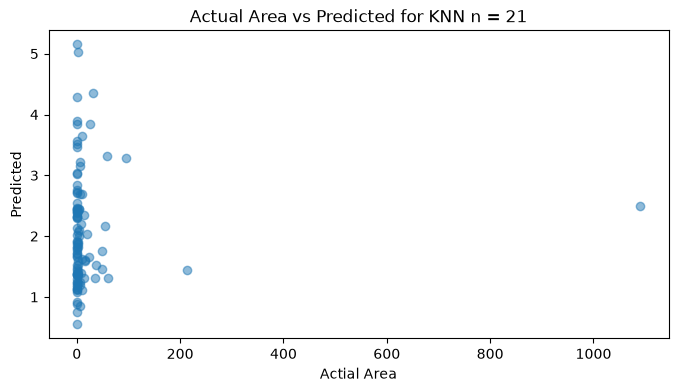

Time Taken ( Random Forest ):  0.17061805725097656


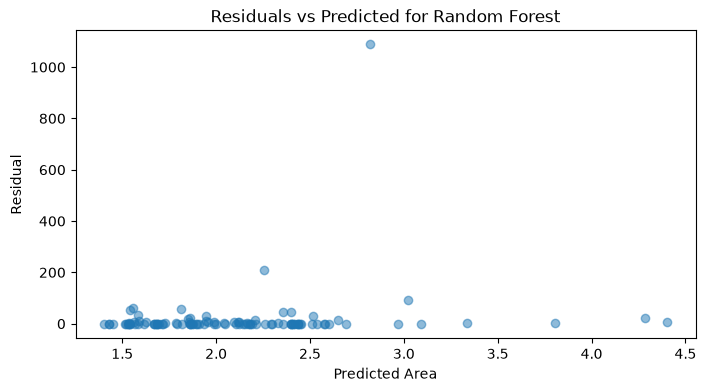

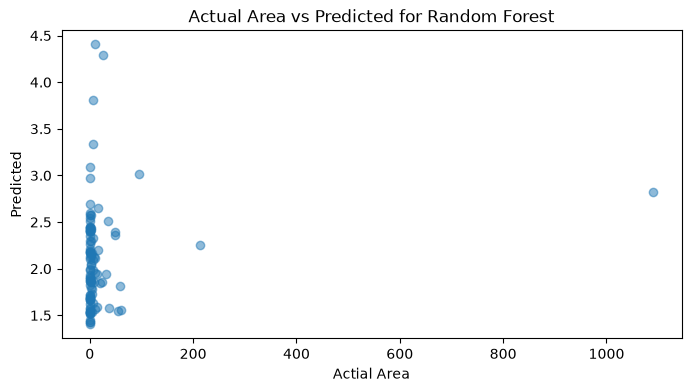

Time Taken ( Random Forest 2 ):  0.20397210121154785


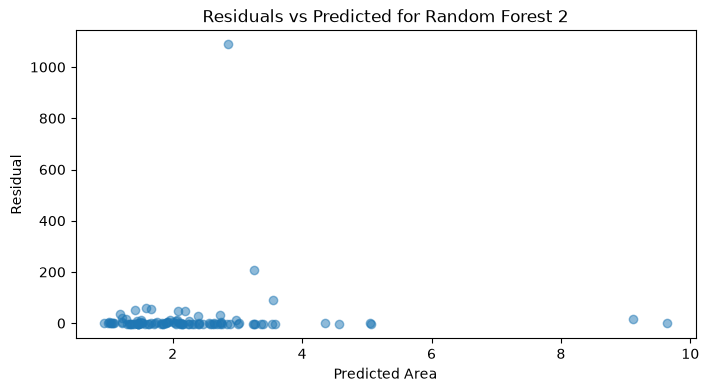

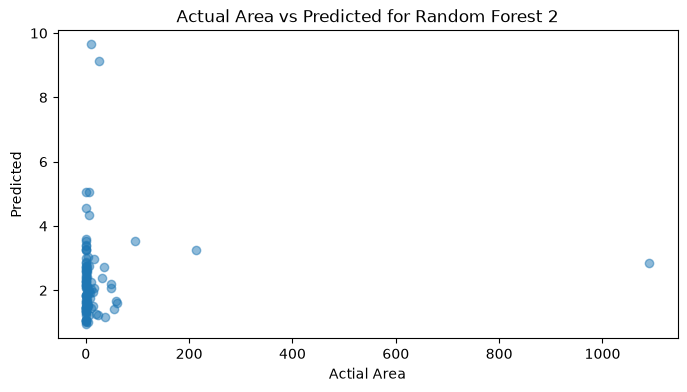

Time Taken ( Random Forest 3 ):  0.24824118614196777


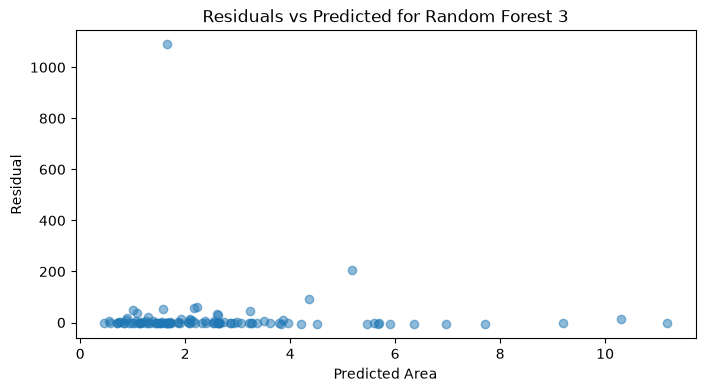

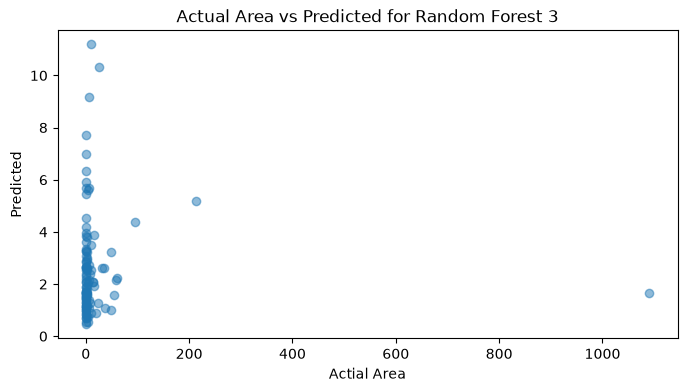

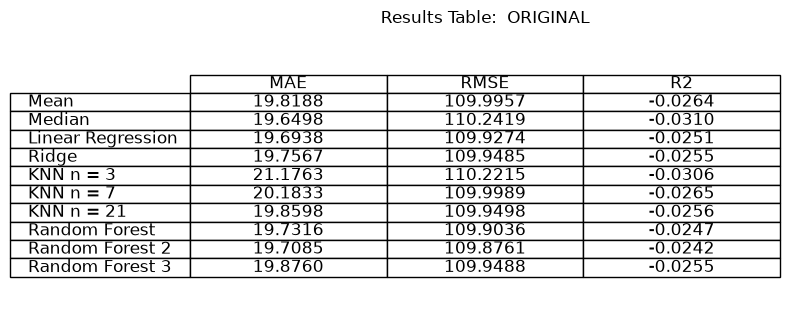

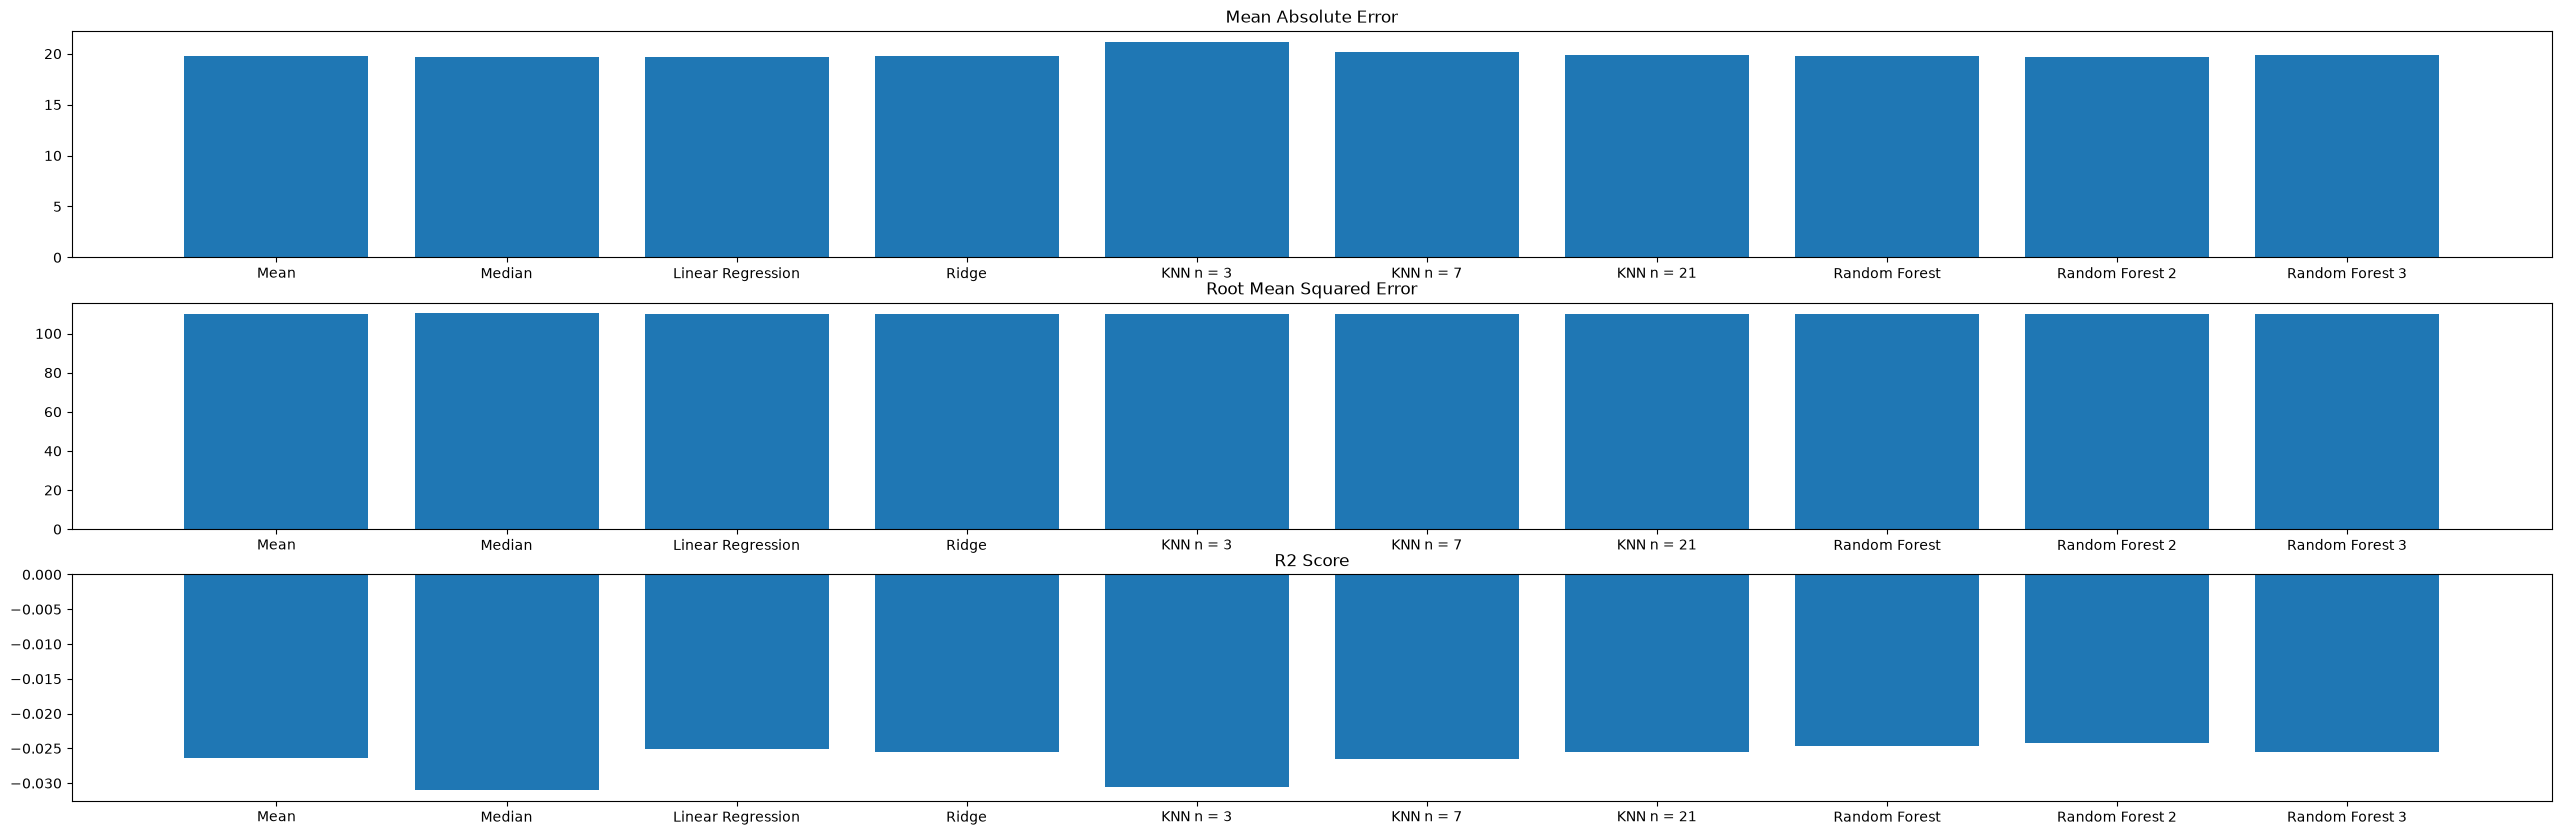

--------------PREPROCESSING:  ALL --------------
Time Taken ( Mean ):  0.035509586334228516


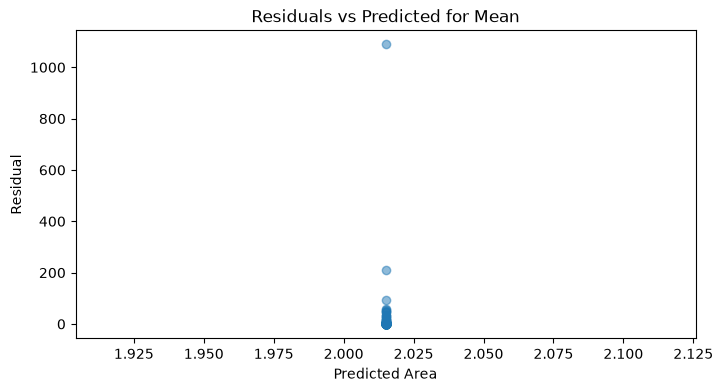

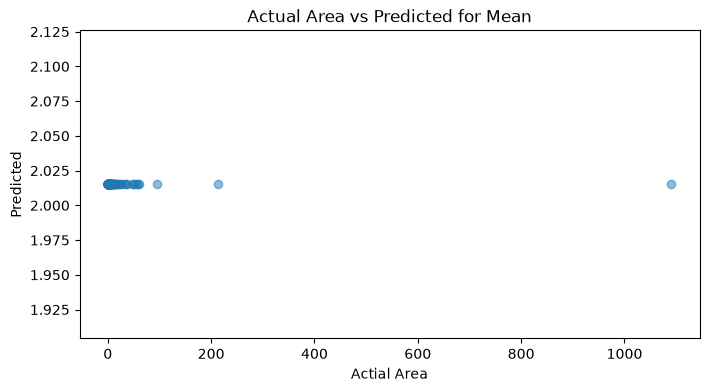

Time Taken ( Median ):  0.045752525329589844


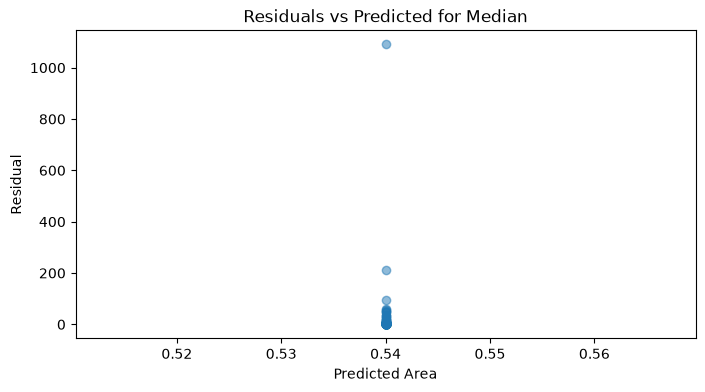

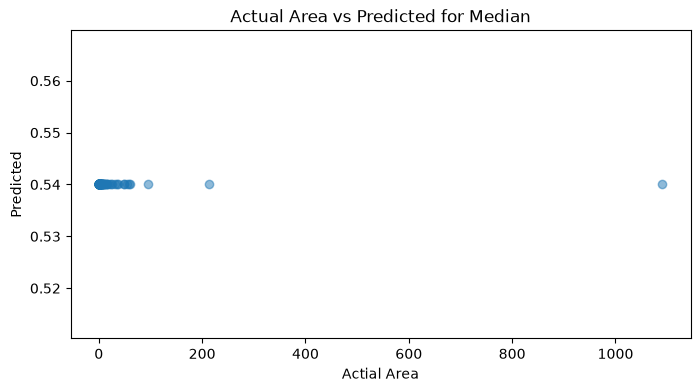

Time Taken ( Linear Regression ):  0.02679896354675293


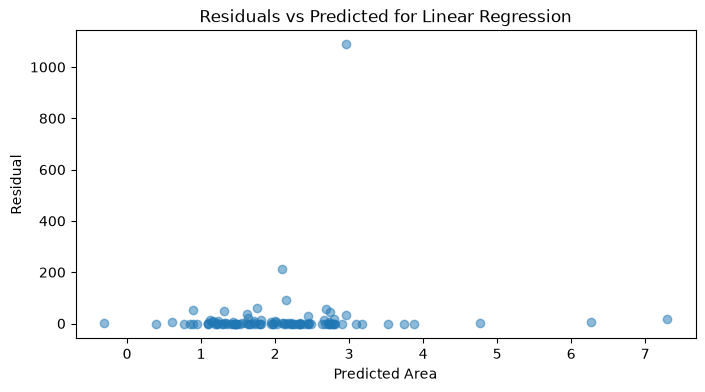

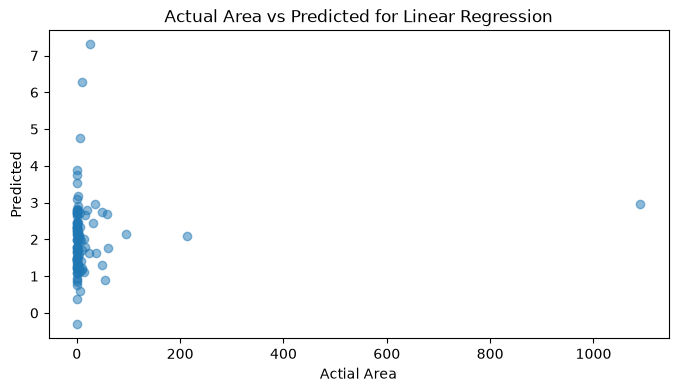

Time Taken ( Ridge ):  0.03261065483093262


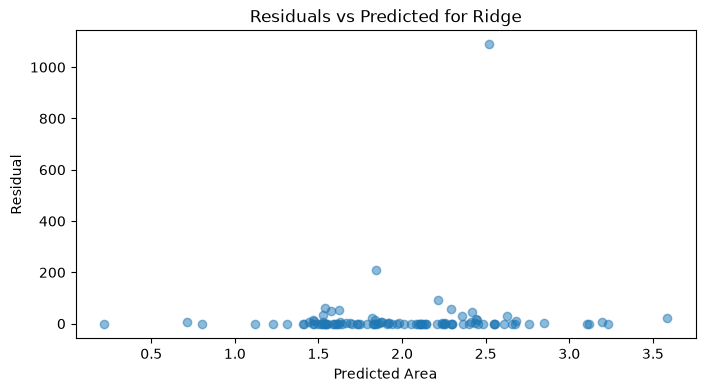

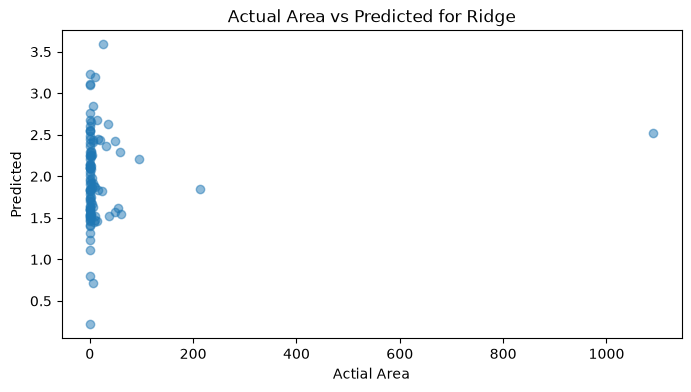

Time Taken ( KNN n = 3 ):  0.03954172134399414


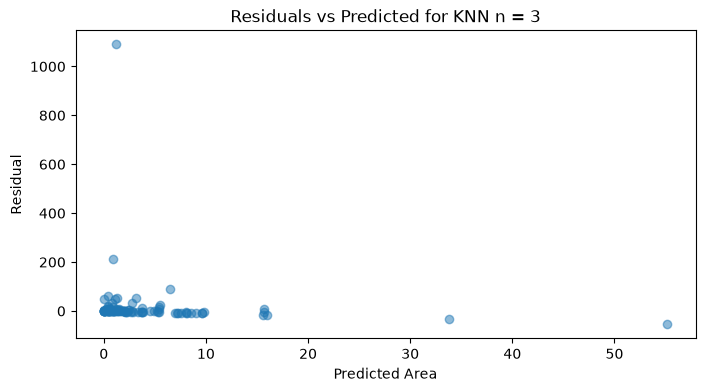

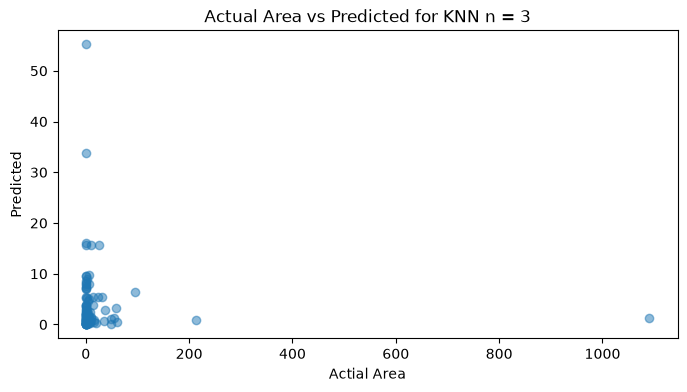

Time Taken ( KNN n = 7 ):  0.029608488082885742


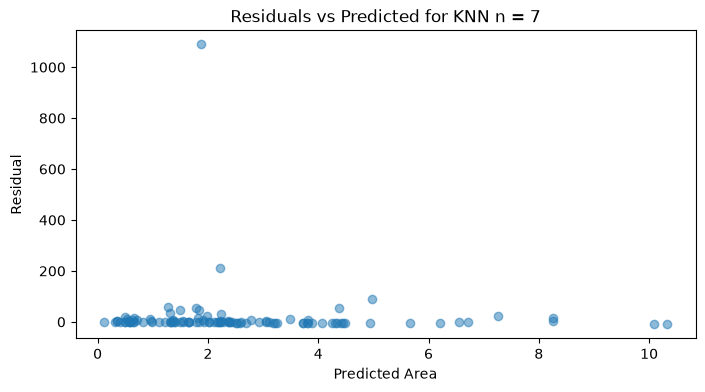

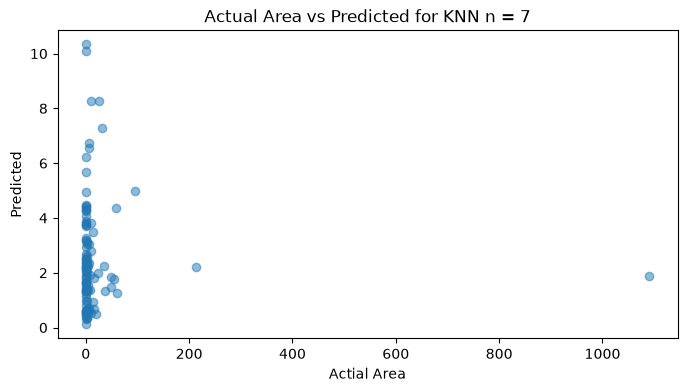

Time Taken ( KNN n = 21 ):  0.030101537704467773


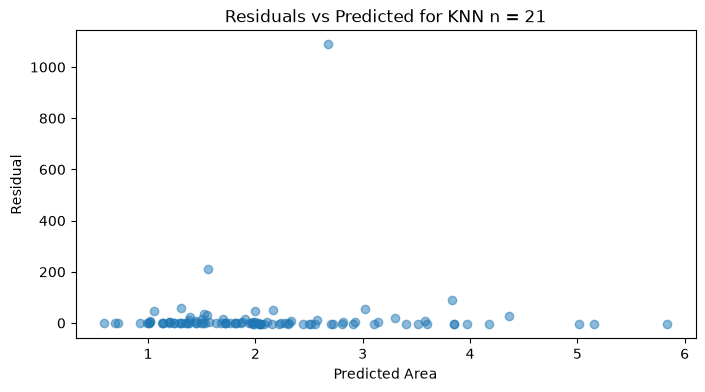

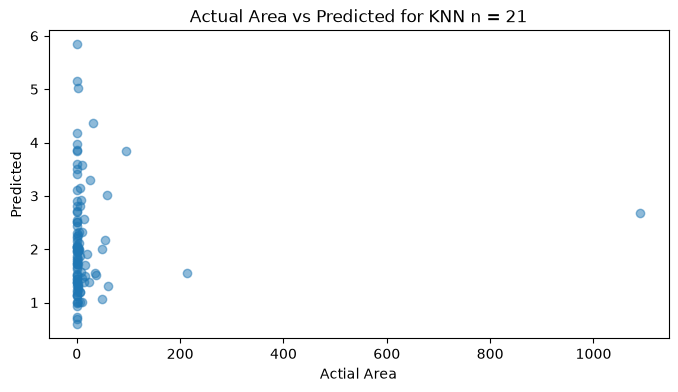

Time Taken ( Random Forest ):  0.15888714790344238


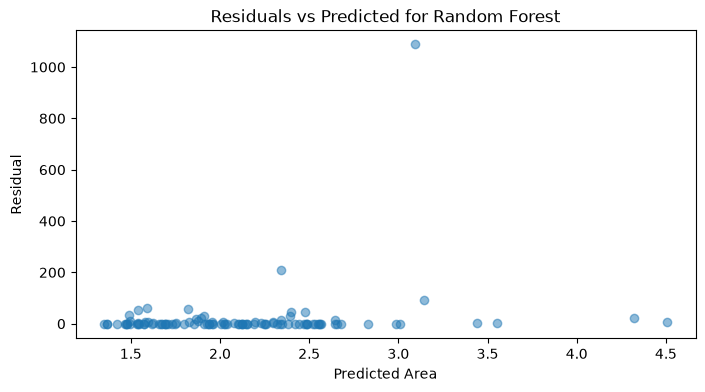

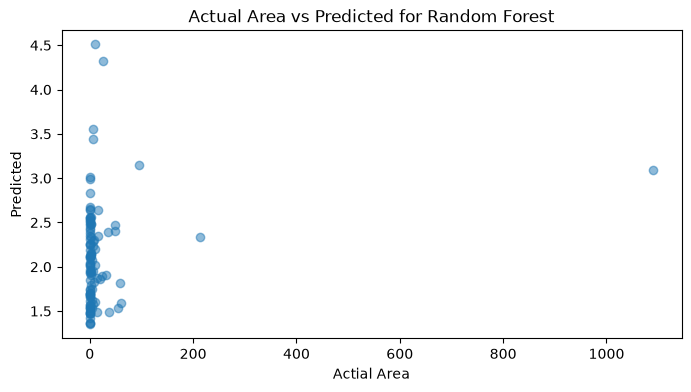

Time Taken ( Random Forest 2 ):  0.20161938667297363


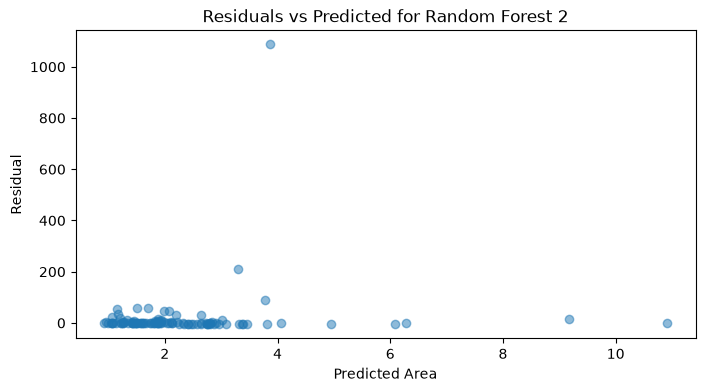

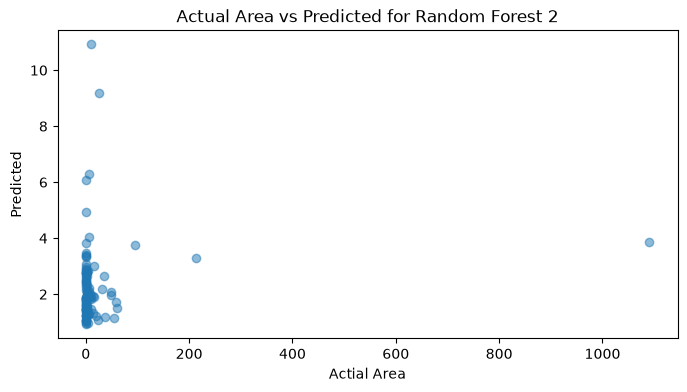

Time Taken ( Random Forest 3 ):  0.26652956008911133


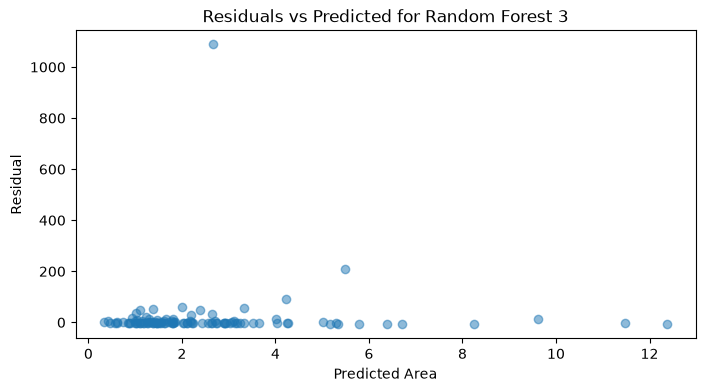

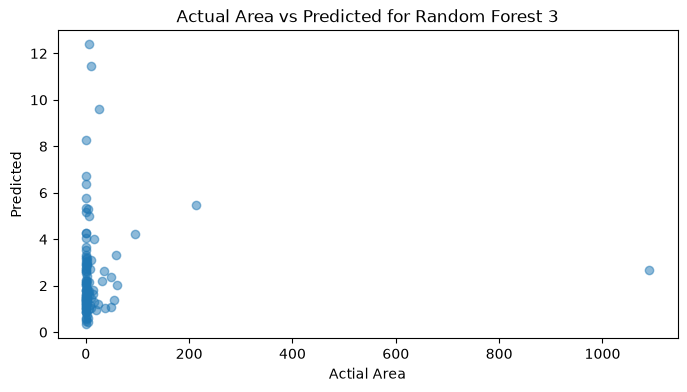

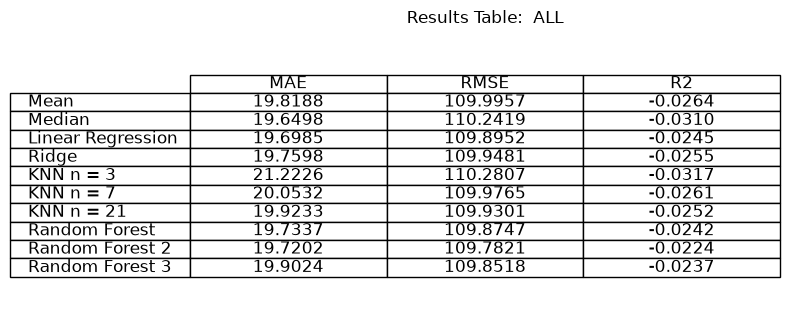

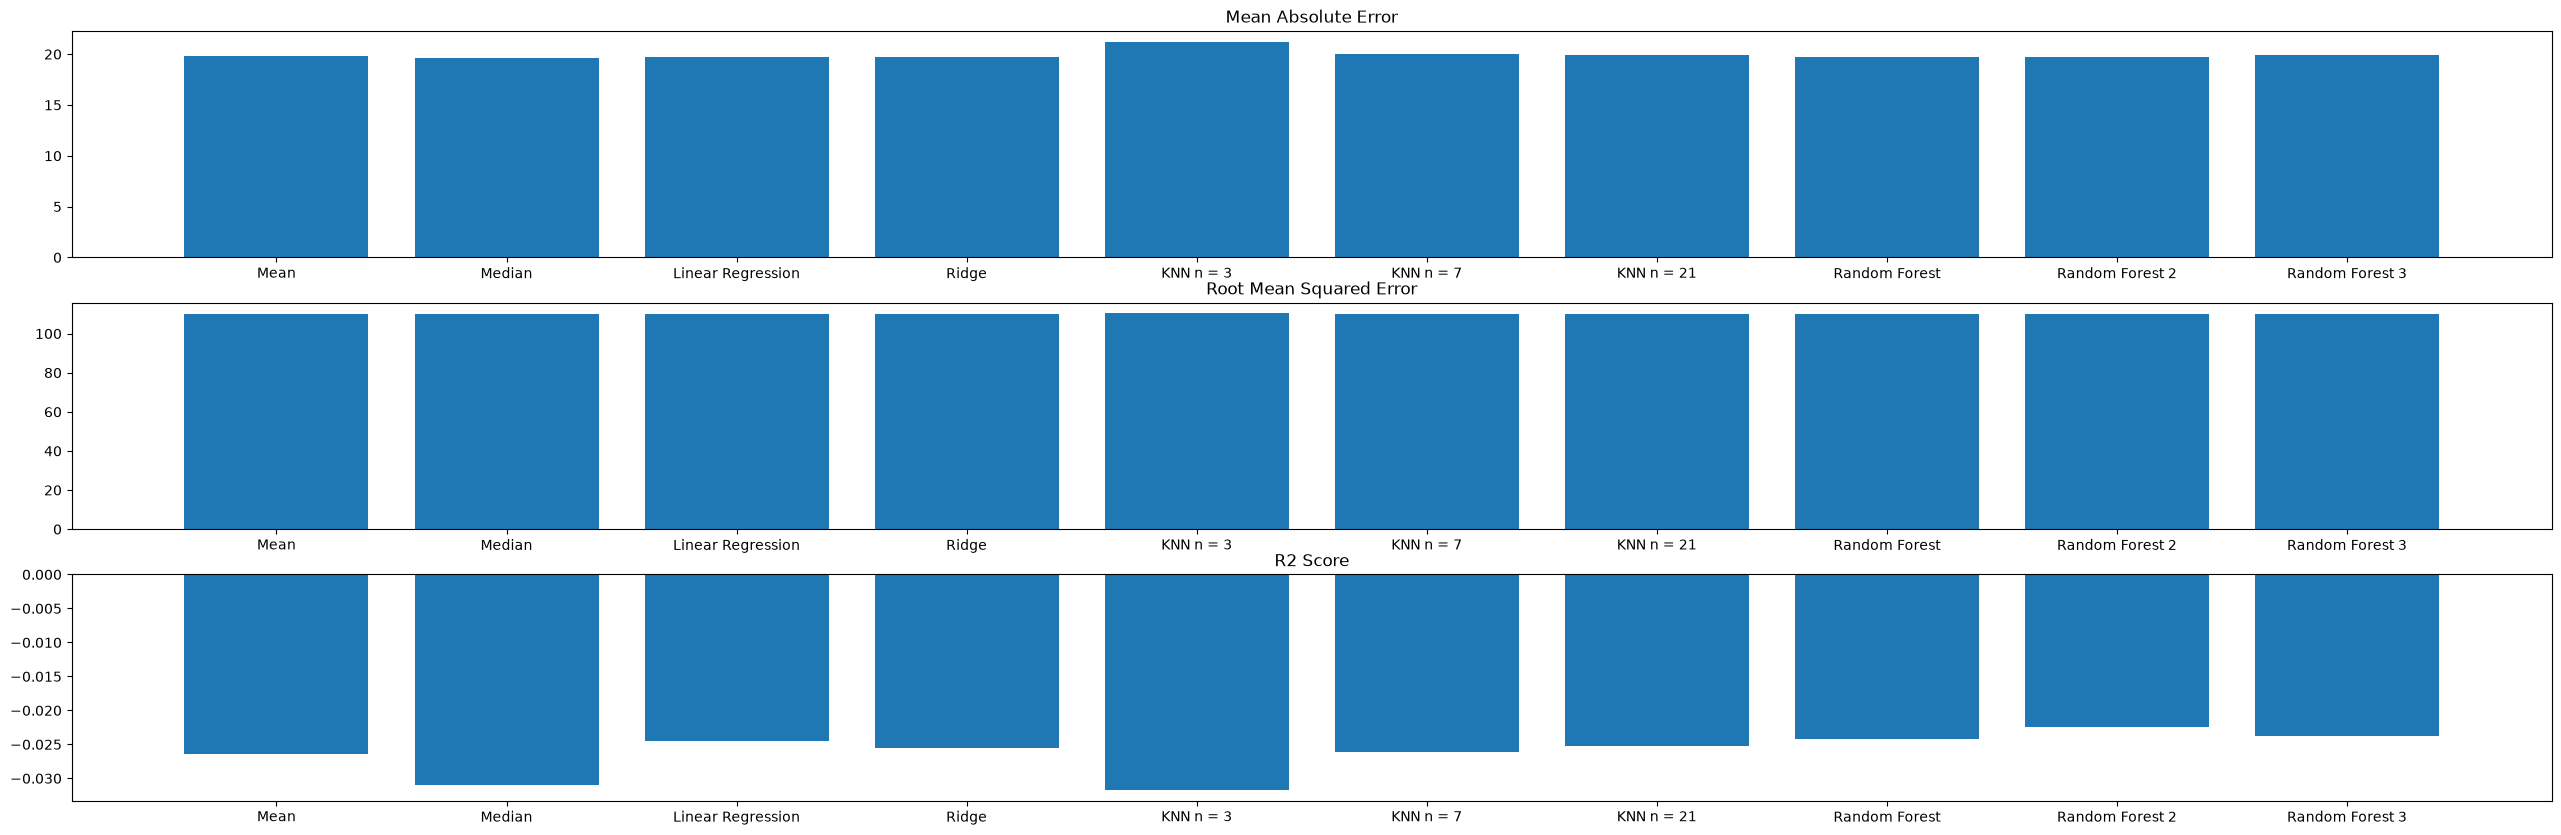

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Time Taken ( Mean ):  0.019257545471191406


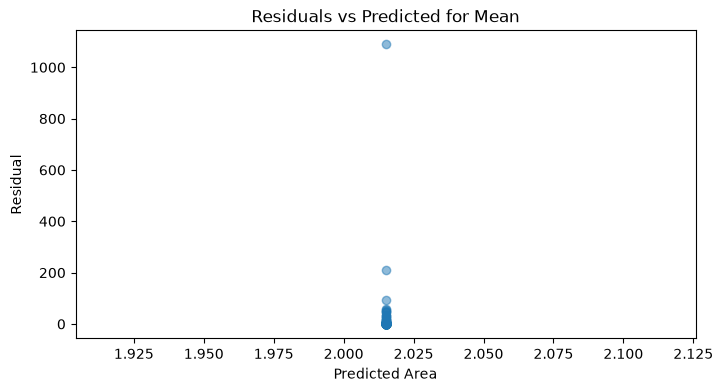

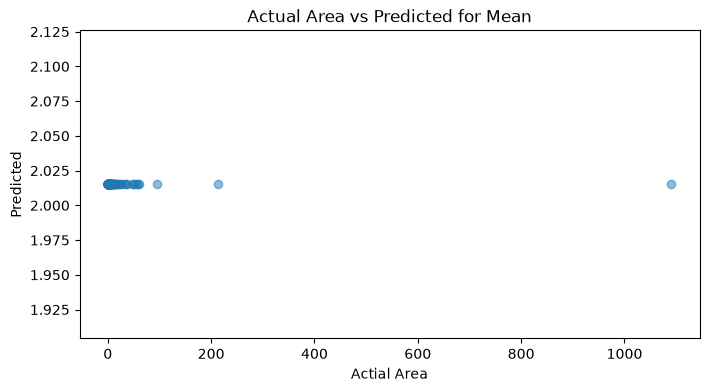

Time Taken ( Median ):  0.018028974533081055


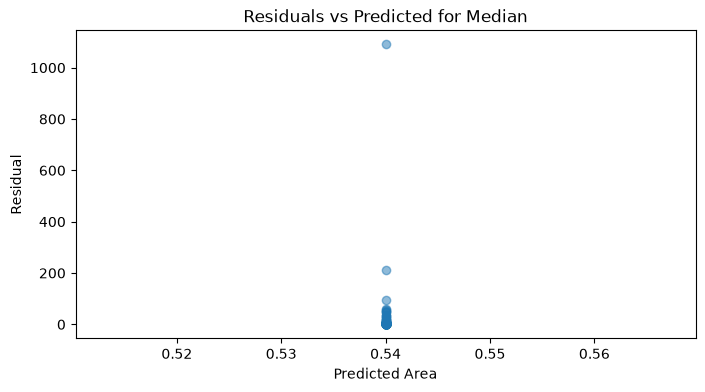

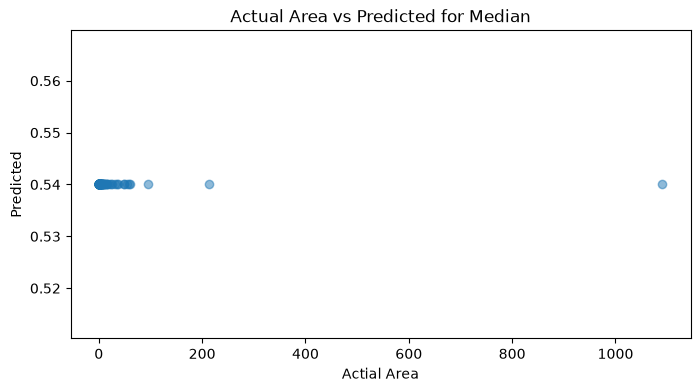

Time Taken ( Linear Regression ):  0.03554248809814453


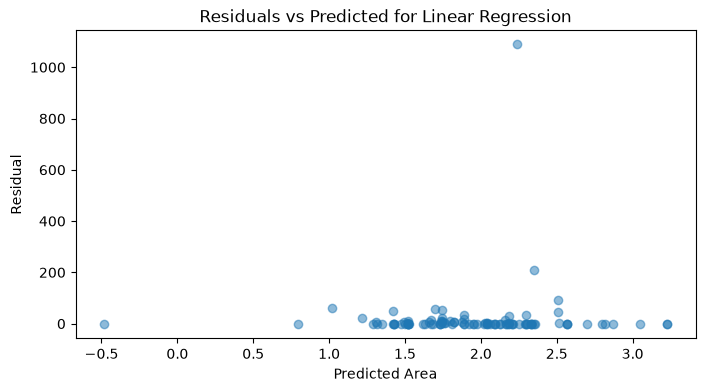

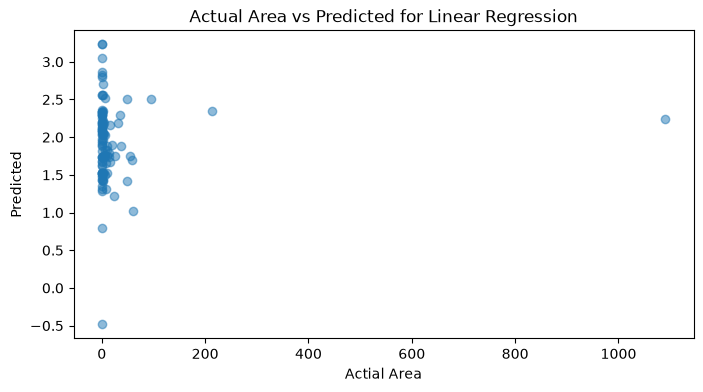

Time Taken ( Ridge ):  0.019563913345336914


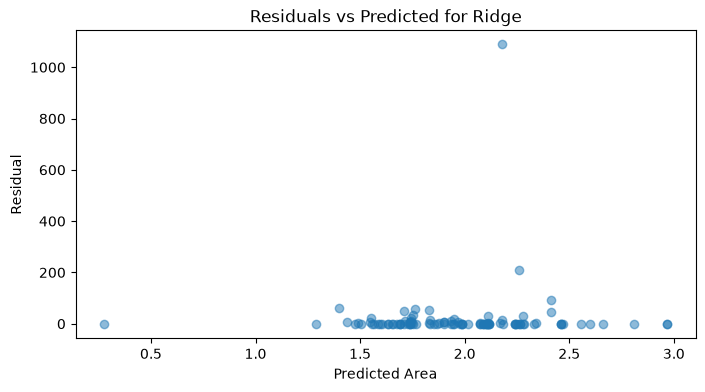

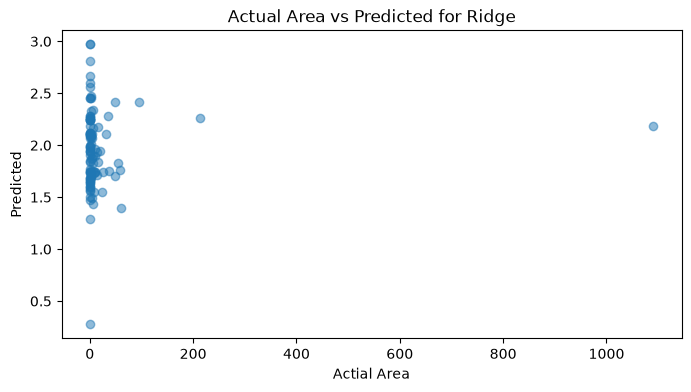

Time Taken ( KNN n = 3 ):  0.02228713035583496


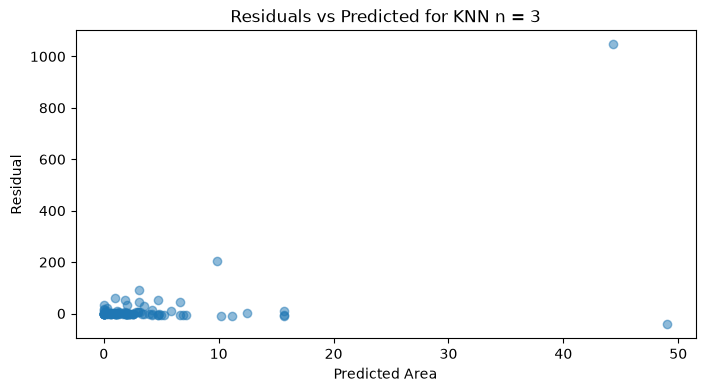

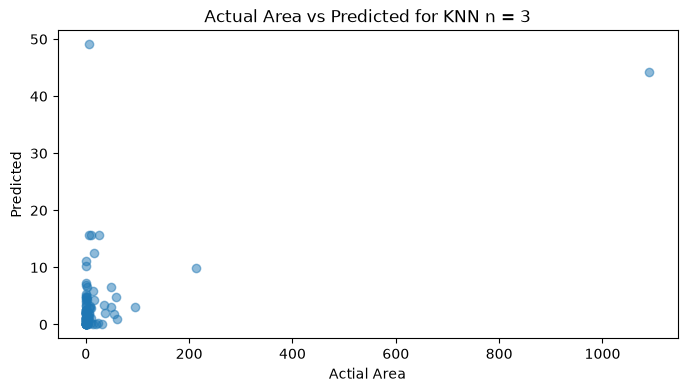

Time Taken ( KNN n = 7 ):  0.019380807876586914


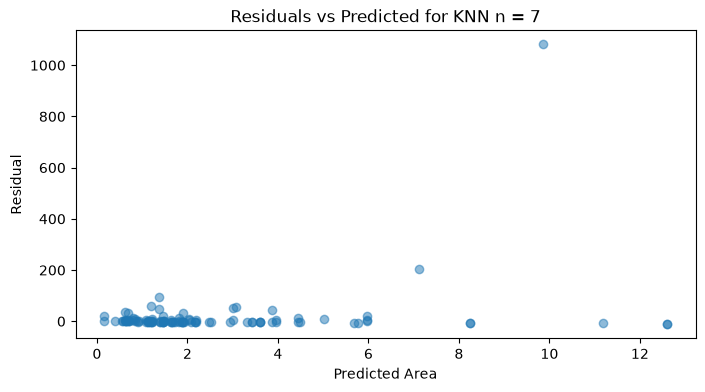

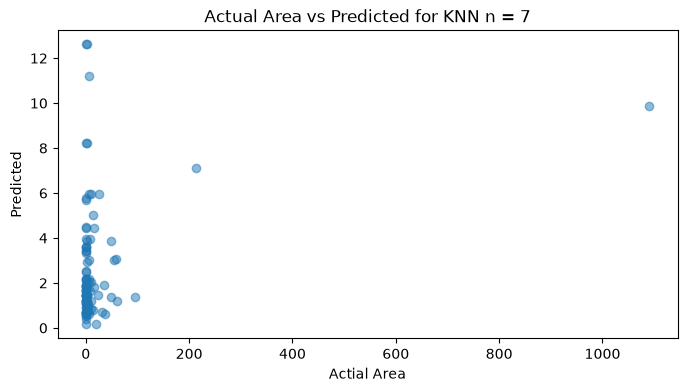

Time Taken ( KNN n = 21 ):  0.01931285858154297


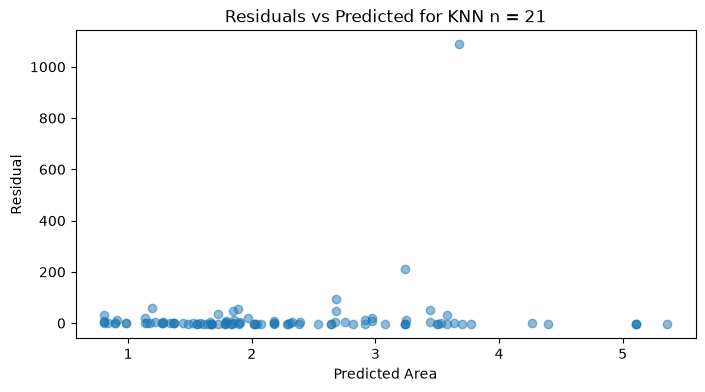

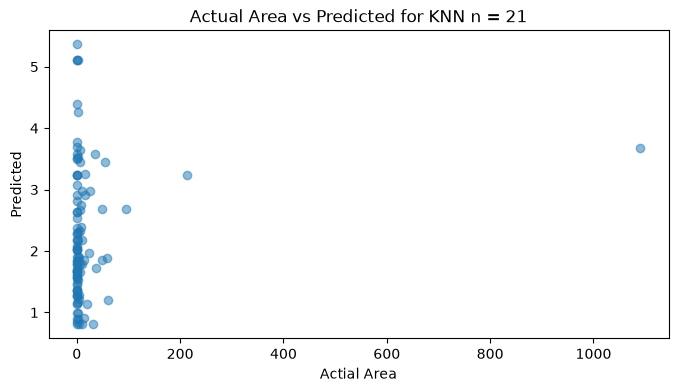

Time Taken ( Random Forest ):  0.13832426071166992


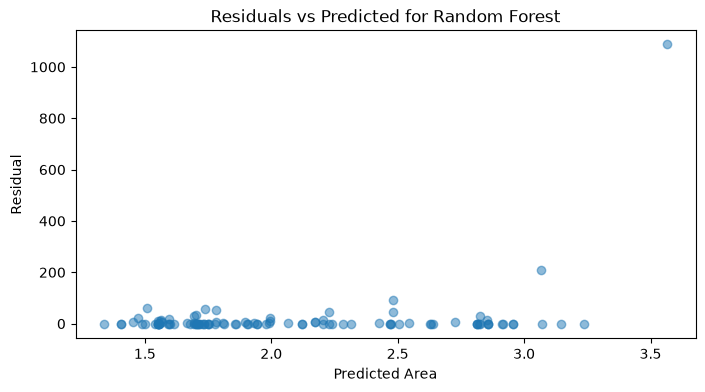

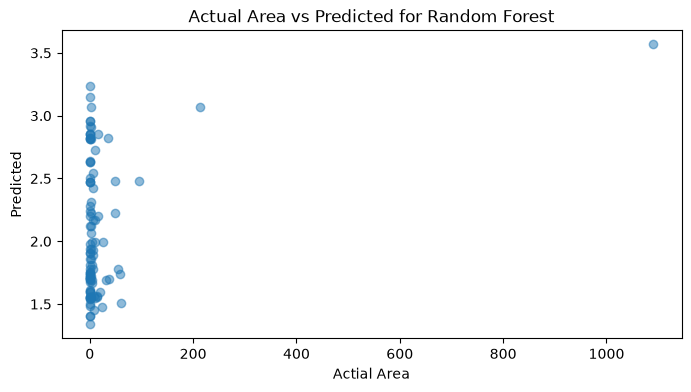

Time Taken ( Random Forest 2 ):  0.16125822067260742


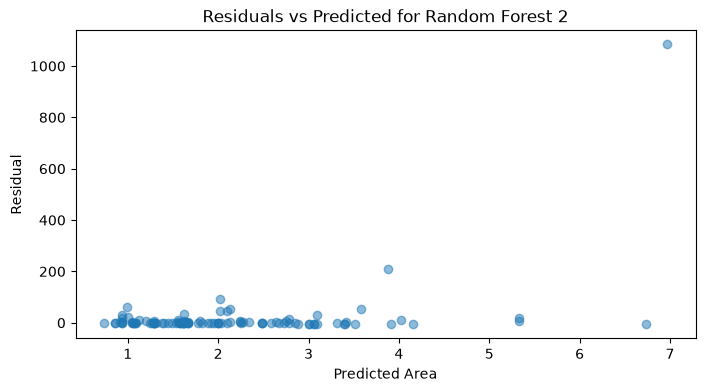

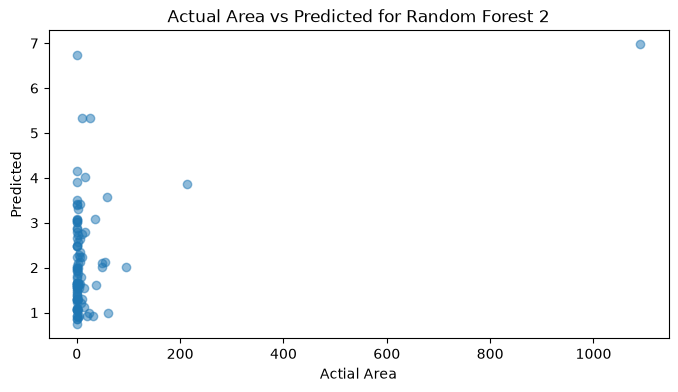

Time Taken ( Random Forest 3 ):  0.18860673904418945


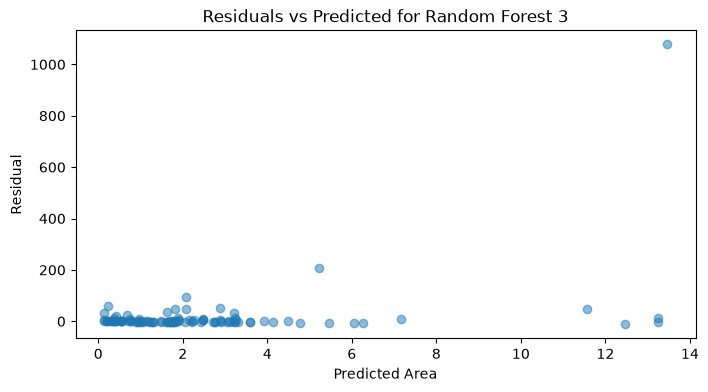

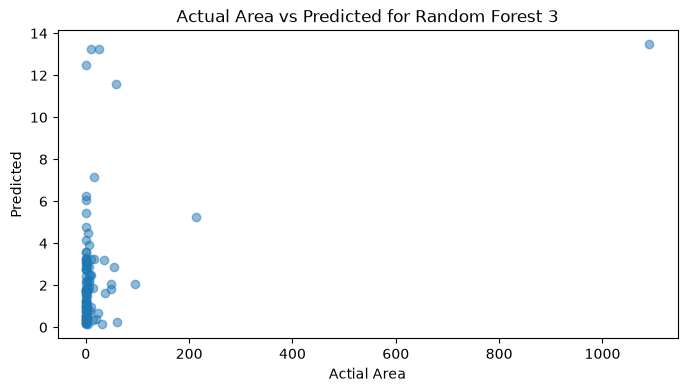

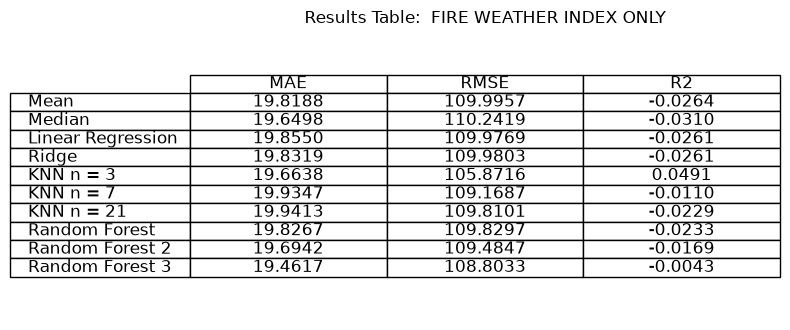

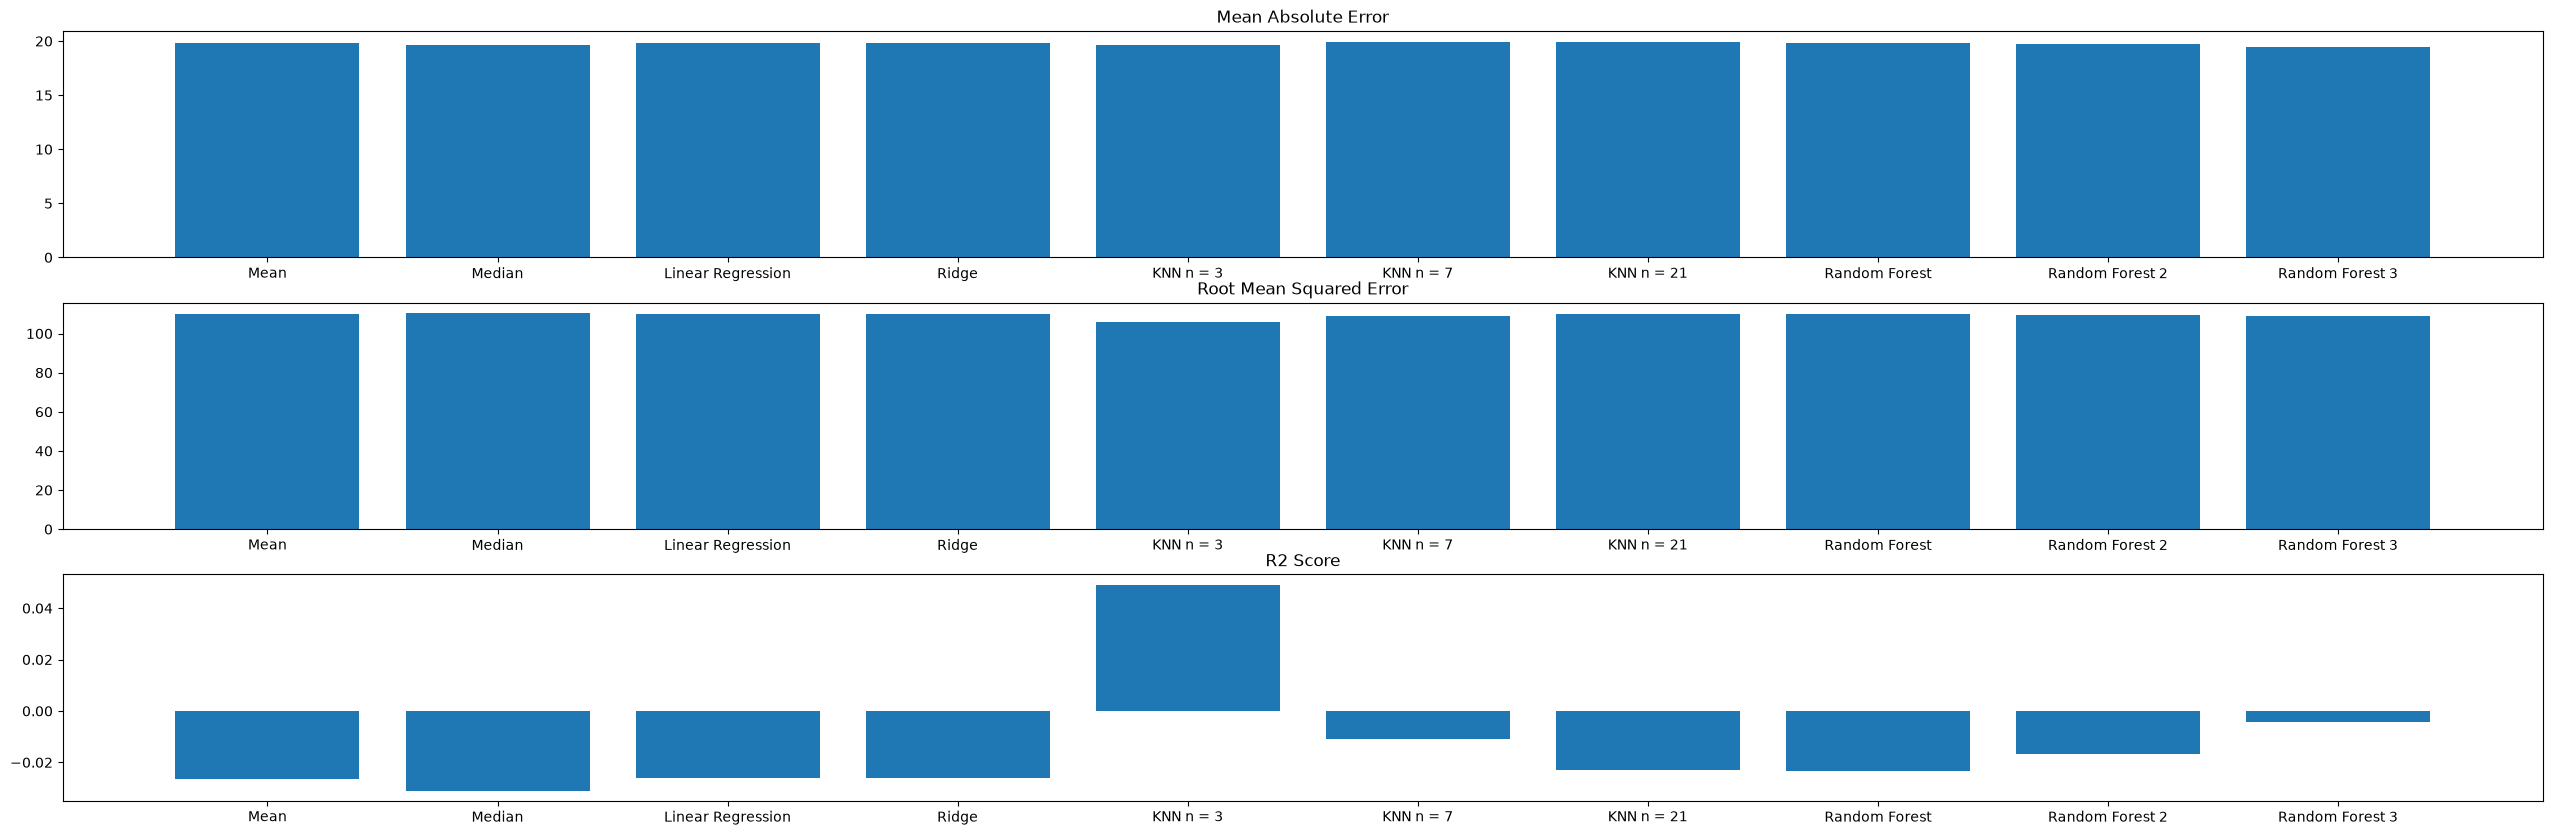

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------
Time Taken ( Mean ):  0.019393444061279297


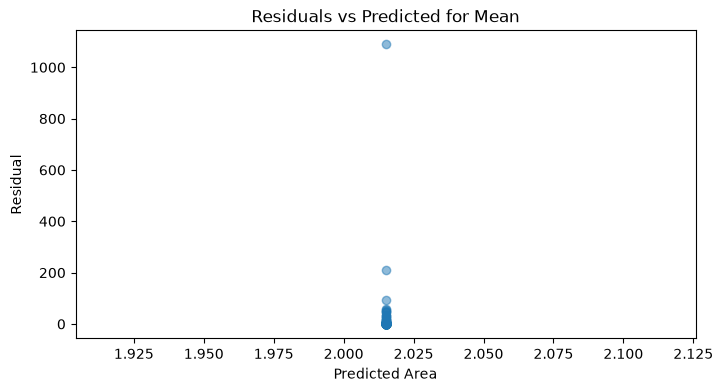

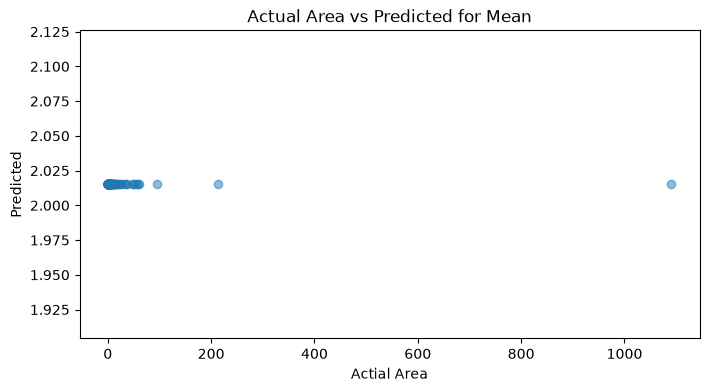

Time Taken ( Median ):  0.020427227020263672


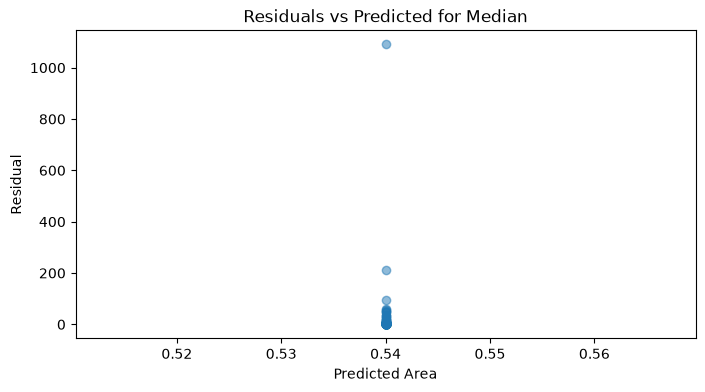

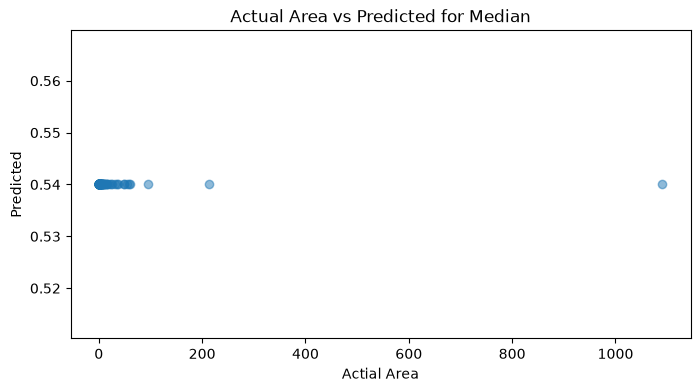

Time Taken ( Linear Regression ):  0.01900625228881836


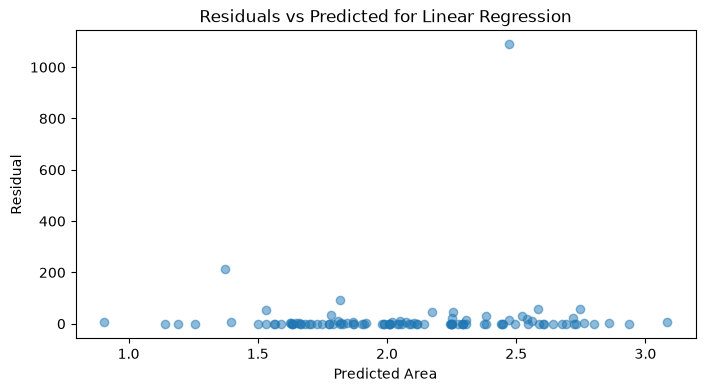

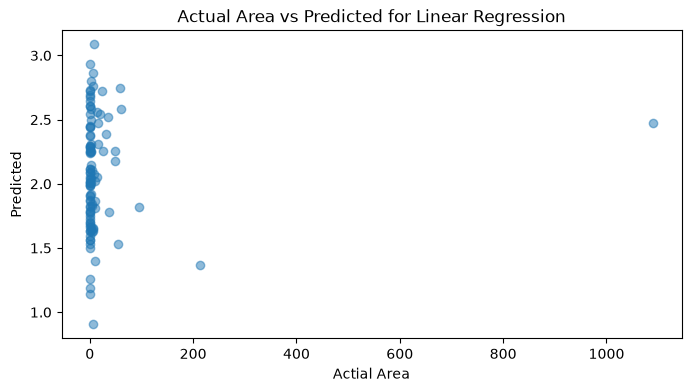

Time Taken ( Ridge ):  0.020904541015625


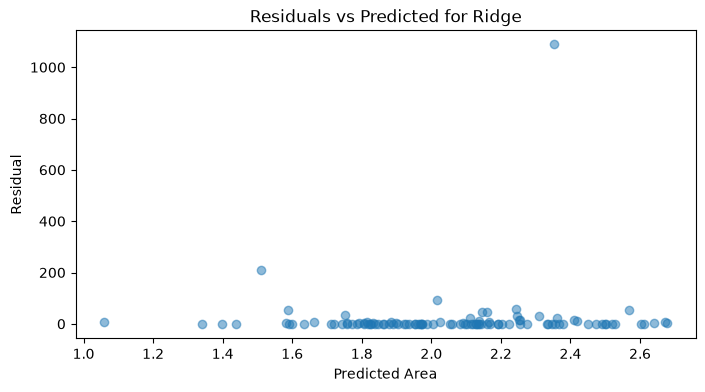

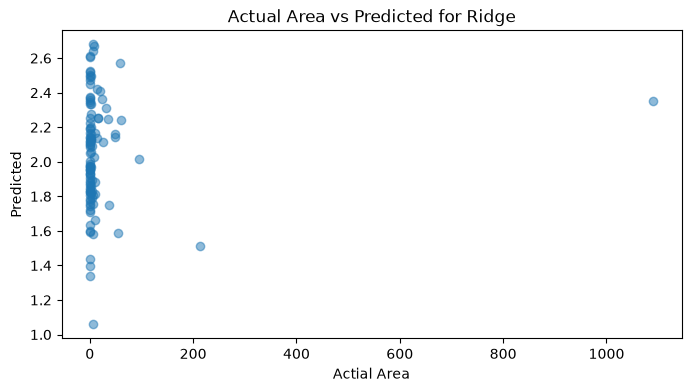

Time Taken ( KNN n = 3 ):  0.019521474838256836


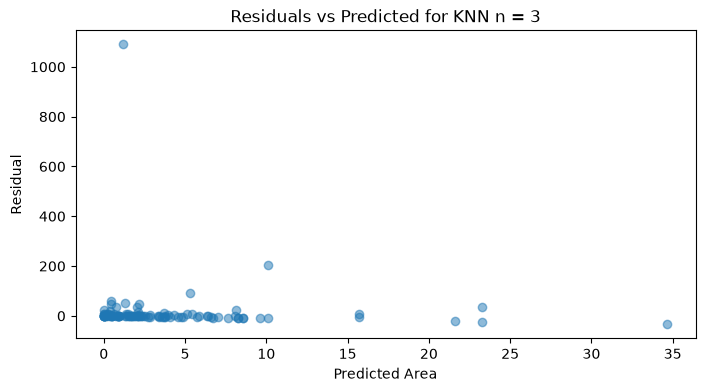

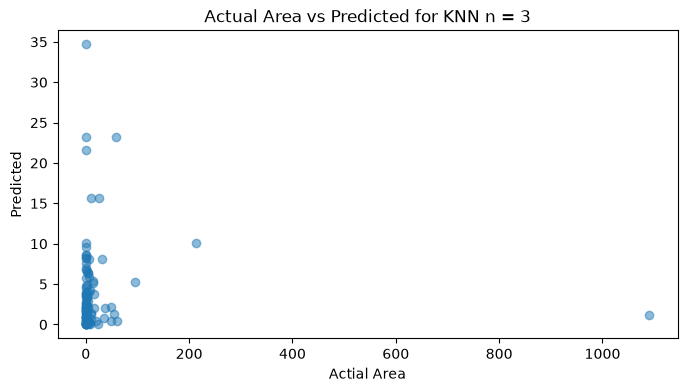

Time Taken ( KNN n = 7 ):  0.020505666732788086


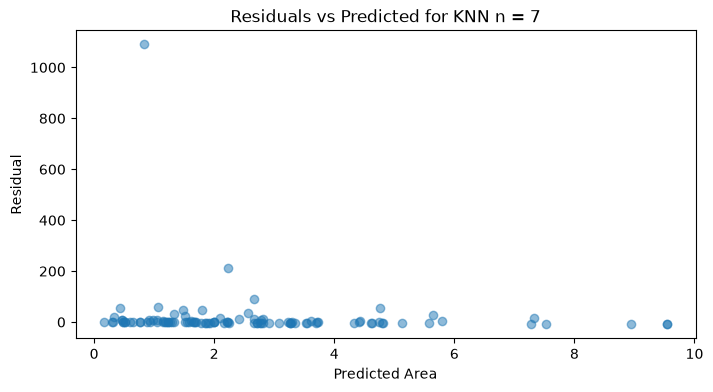

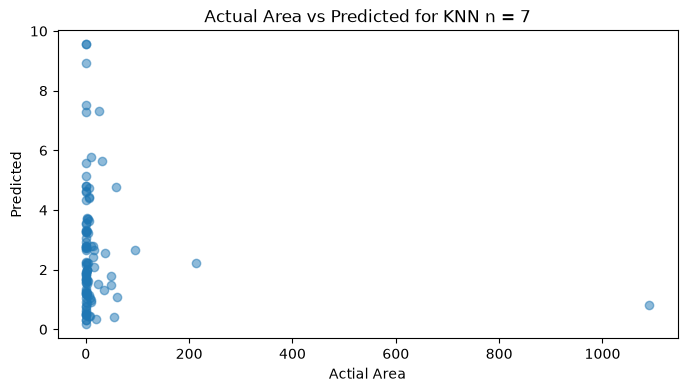

Time Taken ( KNN n = 21 ):  0.020052433013916016


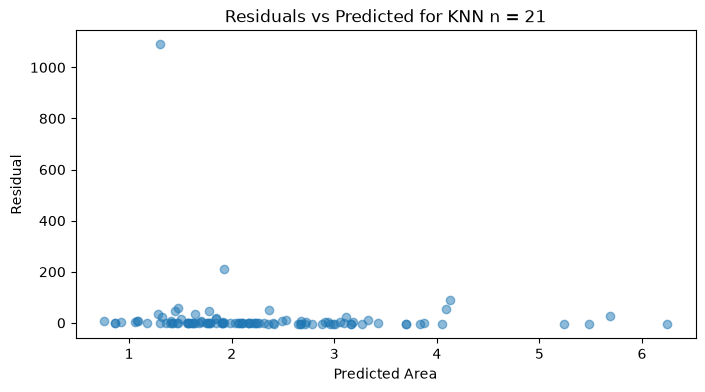

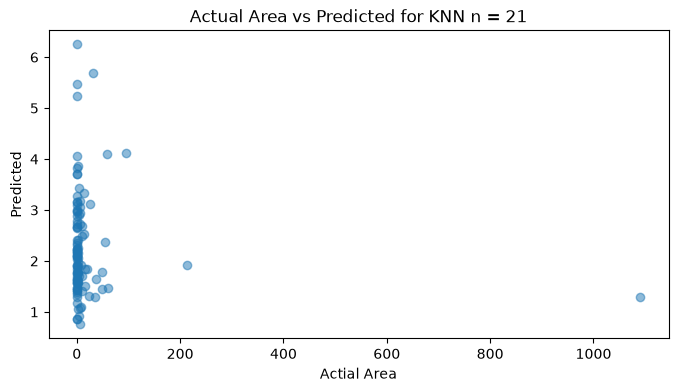

Time Taken ( Random Forest ):  0.15298771858215332


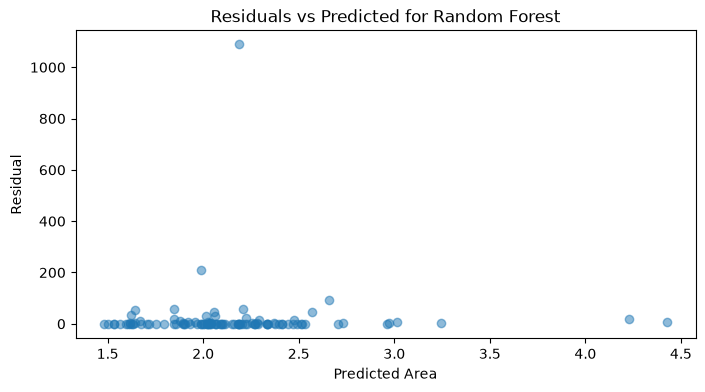

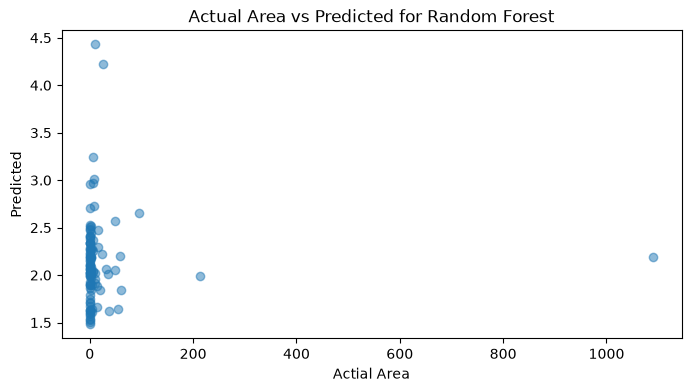

Time Taken ( Random Forest 2 ):  0.1693565845489502


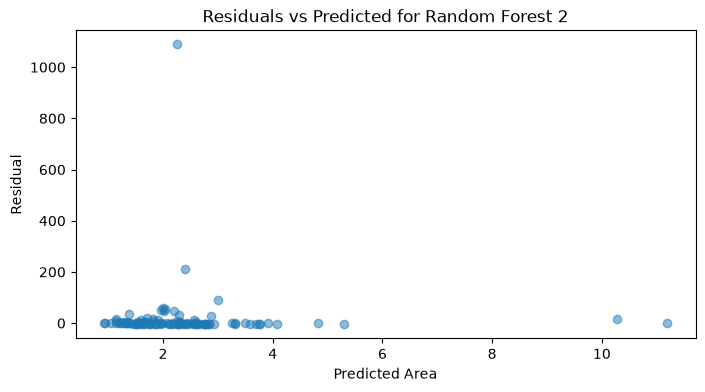

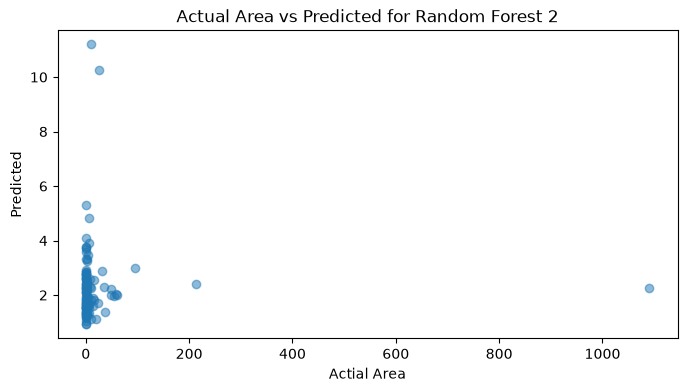

Time Taken ( Random Forest 3 ):  0.23494386672973633


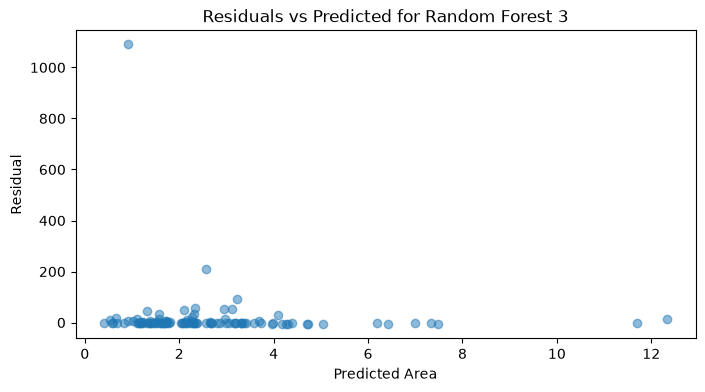

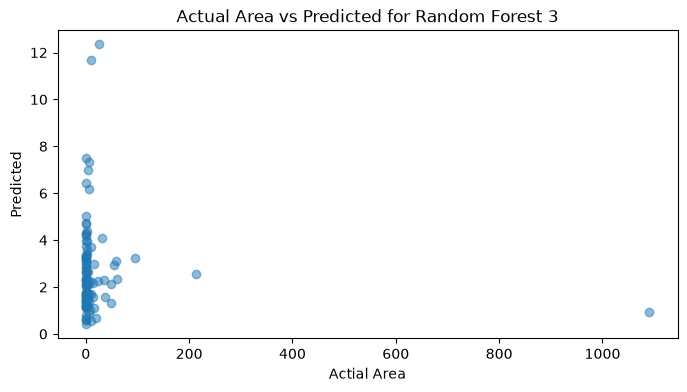

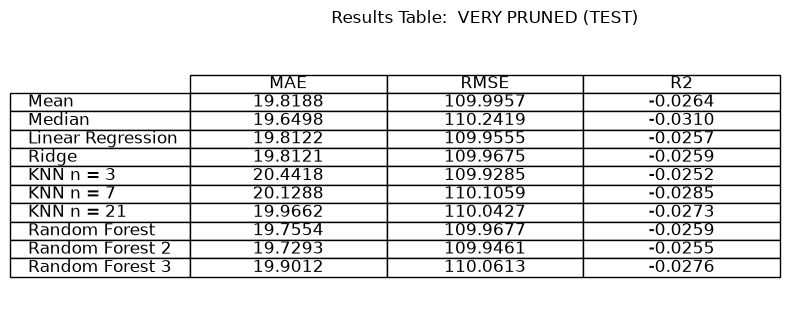

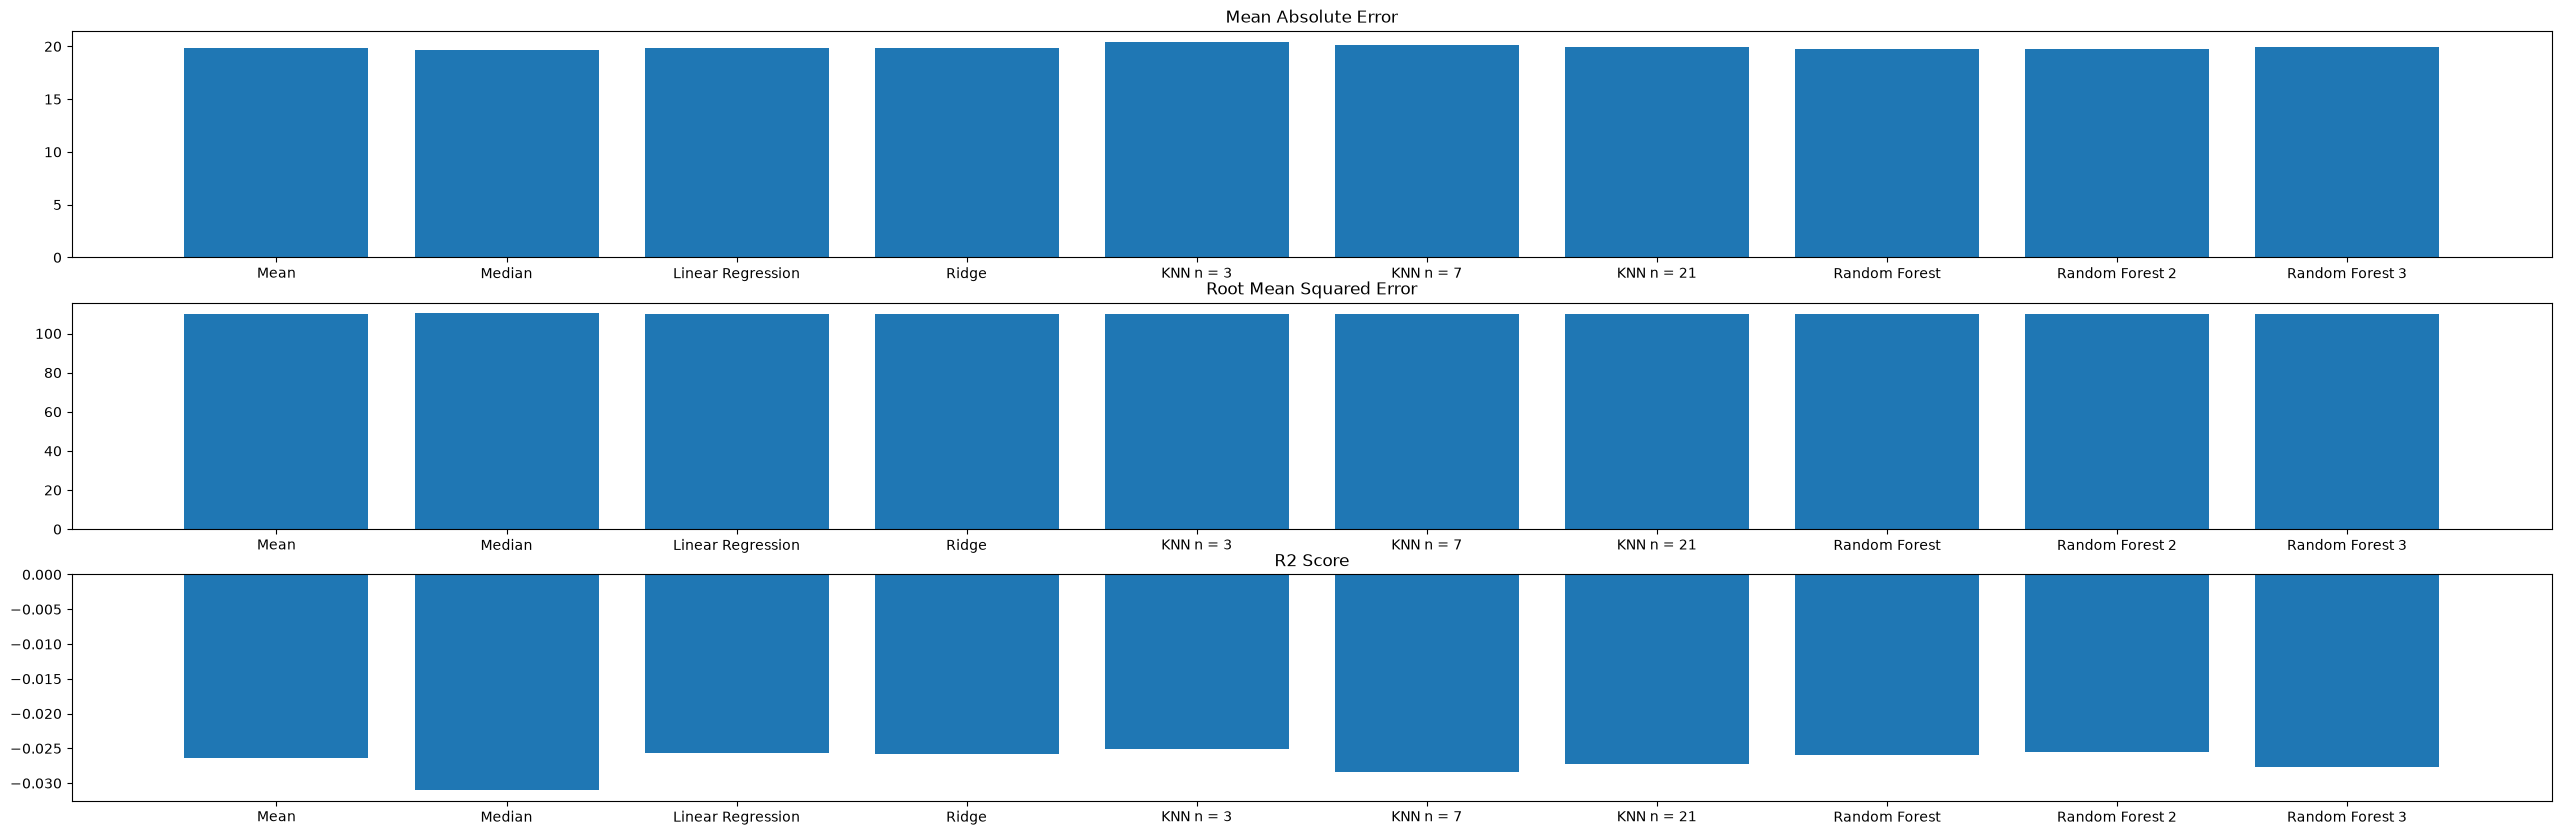

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using train test split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    # Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        
        start_time = time.time()
        
        model.fit(X_train, np.log1p(y_train))
        pred = np.expm1(model.predict(X_test))
        
        elapsed_time = time.time() - start_time
        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
        residuals = (y_test - pred)

        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
        #print("Residuals: ", residuals)
        print("Time Taken (", name, "): ", elapsed_time)
        #print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")
        ## Plot Residual vs Predicted Area
        plt.figure(figsize={8,4})
        plt.scatter(pred, residuals, alpha=0.5)
        plt.xlabel("Predicted Area")
        plt.ylabel("Residual")
        plt.title(f"Residuals vs Predicted for {name}")

        plt.show()

        ## Plot Actual vs Predicted Areas
        plt.figure(figsize={8,4})
        plt.scatter(y_test, pred, alpha=0.5)
        plt.xlabel("Actual Area")
        plt.ylabel("Predicted")
        plt.title(f"Actual Area vs Predicted for {name}")

        plt.show()
        
    #Plot Results
    model_names = list(models.keys())
    plt.figure(figsize={8,0.4 + len(model_names)*0.3})
    plt.axis("off")
    columns = ["MAE", "RMSE", "R2"]
    text = []
    for i in range(len(model_names)):
        text.append([f"{resultsMAE[i]:.4f}",f"{resultsRMSE[i]:.4f}",f"{resultsR2[i]:.4f}"])
    
    table = plt.table(
        cellText = text,
        rowLabels = model_names,
        colLabels = columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    plt.title(f"Results Table:  {title}")
    plt.tight_layout()
    plt.show
    
    plt.figure(figsize={2+len(model_names) * 3,10}) ##Figure is dynamically sized to allow for more models to be added as needed


    plt.subplot(311, title="Mean Absolute Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(model_names)),model_names)

    plt.show()